In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
# Module imports
import numpy as np
import matplotlib.pyplot as plt
import scipy
import scipy.optimize
import scipy.interpolate

import iapws95_light
import iapws95_light.state_rhoT
# import iapws95_light.float_phi_functions as float_phi_functions
# import iapws95_light.float_mix_functions as float_mix_functions

In [3]:
# Example: compute dict w/ saturation curve data (sat. pressure at 630 K)
saturation_tuple:dict = iapws95_light.state_rhoT.prho_sat(630)

print(f"Saturation pressure (MPa): {saturation_tuple['psat']/1e6}")
print(f"Saturated liquid density (kg/m^3): {saturation_tuple['rho_satl']}")
print(f"Saturated vapour density (kg/m^3): {saturation_tuple['rho_satv']}")

Saturation pressure (MPa): 17.968971393767458
Saturated liquid density (kg/m^3): 544.2474174052742
Saturated vapour density (kg/m^3): 132.83955603693164


In [27]:
iapws95_light.state_rhoT.dedv_dedT(400, 500)

{'dedT': 5023.062464195862,
 'dedv': 21864893.461127587,
 'p': 2639195.8717618757,
 'x': 0.01739629843342997}

In [29]:
%timeit iapws95_light.state_rhoT.dedv_dedT(400, 500)

4.57 µs ± 38.3 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


In [31]:
iapws95_light.state_rhoT.u(500, 400)

535255.0328973256

In [ ]:
iapws95_light.state_rhoT.p(500, 400)

27156.479581236003

In [30]:
iapws95_light.state_rhoT.s(500, 400)

1608.2497780473188

In [32]:
iapws95_light.state_rhoT.prho_sat(340)

{'psat': 27187.814263472283,
 'rho_satl': 979.503448491748,
 'rho_satv': 0.1744023656641645}

In [33]:
iapws95_light.state_rhoT.h(500, 400)

535746.5715884579

In [34]:
iapws95_light.state_rhoT.c_p(500, 400)


4252.904423491898

In [ ]:
%timeit all_pure_lv(1001, 340)

25.5 µs ± 124 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


## Legacy

In [14]:
# Compute saturation curves
T_sample_sat = np.linspace(0.01 + 273.15, iapws95_light.Tc-0.01, 100)
sat_triples = [iapws95_light.prho_sat(T) for T in T_sample_sat]
psat_samples, rhol_samples, rhov_samples = zip(
  *[(tup["psat"], tup["rho_satl"], tup["rho_satv"])
  for tup in sat_triples])
# Compute dependent variables along saturation curves
sl, hl, ul, wl, pl = np.array([all_pure_lv(rhol, T)
                       for (rhol, T) in zip(rhol_samples, T_sample_sat)]).T
sv, hv, uv, wv, pv = np.array([all_pure_lv(rhov, T)
                       for (rhov, T) in zip(rhov_samples, T_sample_sat)]).T

# Compute atmospheric boiling temperature
p_atm = 1e5
T_boil_atm = float(scipy.optimize.fsolve(
  lambda T: float(iapws95_light.prho_sat(T)["psat"]) / p_atm - 1,
                            273.15 + 100))

# Compute h-s data for coexistence region (liquid + vapor phases)
# NOTE: sl is the entropy of liquid at saturation temperature, different
# from the entropy of a point in the pure liquid (subcooled liquid) region, s_L.
# Similarly, sv is the entropy of saturated vapor, different from the entropy
# of a point in the pure vapor (superheated vapor) region, s_V.
psat_atm, rhol_atm, rhov_atm = iapws95_light.prho_sat(T_boil_atm).values()
sl_atm, hl_atm, _, _, _ = all_pure_lv(rhol_atm, T_boil_atm)
sv_atm, hv_atm, _, _, _ = all_pure_lv(rhov_atm, T_boil_atm)

# Compute T-s data for pure LIQUID region of atmospheric isobar
T_L_atm = np.linspace(273.15+1, T_boil_atm, 100)[:-1]
s_L_atm = np.zeros_like(T_L_atm)
for i, TL in enumerate(T_L_atm):
  rhol = scipy.optimize.brenth(
    lambda rho: all_pure_lv(rho, TL)[4] / p_atm - 1.0,
    1.00000*iapws95_light.prho_sat(TL)["rho_satl"],
    1.001*iapws95_light.prho_sat(TL)["rho_satl"]
  )
  s_L_atm[i] = all_pure_lv(rhol, TL)[0]

# Compute T-s data for pure VAPOR region of atmospheric isobar
T_V_atm = np.linspace(T_boil_atm, 300 + 273.15, 100)[1:]
s_V_atm = np.zeros_like(T_V_atm)
for i, TV in enumerate(T_V_atm):
  rhov = scipy.optimize.brenth(
    lambda rho: all_pure_lv(rho, TV)[4] / p_atm - 1.0,
    0.00001*iapws95_light.prho_sat(TV)["rho_satv"],
    1.00000*iapws95_light.prho_sat(TV)["rho_satv"]
  )
  s_V_atm[i] = all_pure_lv(rhov, TV)[0]

# Compute T-s for liquid-vapor coexistence region
x_range_atm = np.linspace(0, 1, 100)
s_LV_atm = x_range_atm * sv_atm + (1 - x_range_atm) * sl_atm
T_LV_atm = np.full_like(s_LV_atm, T_boil_atm)

# Compute regions to obtain T-s curve of the atmospheric isobar
s_atm_isobar = np.concatenate((s_L_atm, s_LV_atm, s_V_atm,))
T_atm_isobar = np.concatenate((T_L_atm, T_LV_atm, T_V_atm,))

# Compute isobar at depth in T-s (supercritical)
T_depth_range = np.linspace(274, 1600, 100)
rho_depth = np.zeros_like(T_depth_range)
s_depth = np.zeros_like(T_depth_range)
p_depth_check = np.zeros_like(T_depth_range)
p_depth = 5000 * 9.8 * 1000
for i, T in enumerate(T_depth_range):
  rho_depth[i] = scipy.optimize.fsolve(
    lambda rho:all_pure_lv(rho, T)[4] / p_depth - 1.0,
    1000
  )
  s_depth[i], _, _, _, p_depth_check[i] = all_pure_lv(rho_depth[i], T)

# Critical point entropy
sc = all_pure_lv(iapws95_light.rhoc, iapws95_light.Tc)[0]

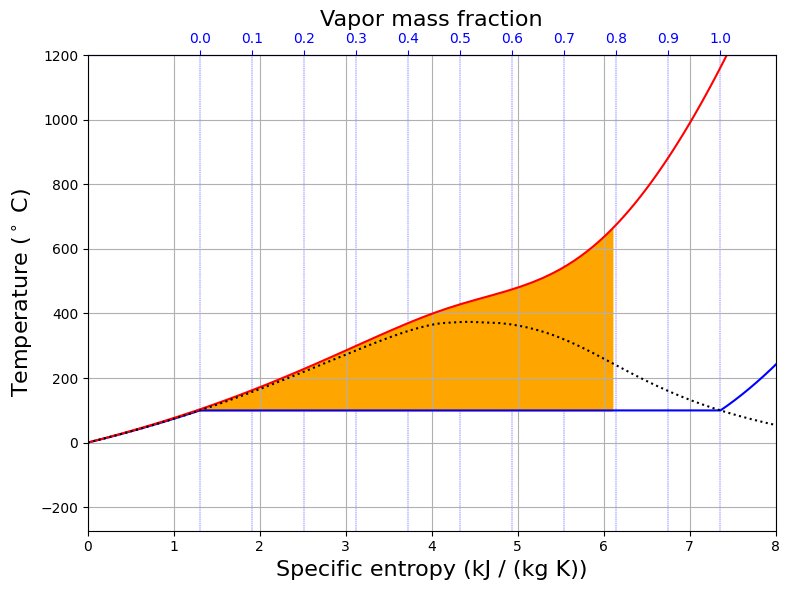

In [15]:
''' Plot example engine cycle '''
plt.figure(figsize=(8, 6), dpi=100)
s_scale = 1000
T_shift = -273.15
plt.plot(s_atm_isobar / s_scale, T_atm_isobar + T_shift, 'b')
plt.plot(s_depth / s_scale, T_depth_range + T_shift, 'r')
plt.plot(np.concatenate((sl, sv[::-1],)) / s_scale,
         np.concatenate((T_sample_sat , T_sample_sat[::-1],)) + T_shift, 'k:')
plt.xlim(0, 8000 / s_scale)
plt.ylim(T_shift, 1200)

s_range_plot = np.linspace(sl_atm, 6100, 100)
plt.fill_between(s_range_plot / s_scale,
                 np.full_like(s_range_plot, T_boil_atm + T_shift),
                 np.interp(s_range_plot / s_scale, s_depth / s_scale,
                           T_depth_range) + T_shift, color="orange")
plt.grid()

secax = plt.gca().secondary_xaxis('top',
  functions=(lambda s: (1e3*s - sl_atm) / (sv_atm - sl_atm),
             lambda x: (sl_atm + x * (sv_atm - sl_atm) / 1e3)))
# Set ticks on vapor mass fraction access
mass_frac_ticks = np.arange(0, 1.01, 0.1)
secax.xaxis.set_major_locator(plt.FixedLocator(mass_frac_ticks))

# Grid line mapping
grid_lines_x = (sl_atm + mass_frac_ticks * (sv_atm - sl_atm)) / 1e3
secax.set_xlabel("Vapor mass fraction", fontsize=16)
secax.spines["top"].set_color("blue")
secax.tick_params(colors="blue")
for x in grid_lines_x:
  plt.gca().axvline(x, zorder=-1, color='b', linestyle='--', linewidth=0.3)

plt.xlabel("Specific entropy (kJ / (kg K))", fontsize=16)
plt.ylabel("Temperature (${}^\circ$ C)", fontsize=16)
plt.tight_layout()

In [16]:
# Set boundary pressure conditions and pressure gradient driving flow
p_surf = 1e5
p_base = 100e6
z_base = -5e3
dpdz_avg = (p_base - p_surf) / z_base

# Define governing equation in rate form (that can be plugged in ODE solver)
def dhdz(rho1, T1, rho2, T2, gamma):
  ''' Rate of enthalpy change in +z direction (upward).
      This is the governing equation '''
  dhdz1 = -gamma * (T1 - T2) + (1/rho1) * dpdz_avg
  dhdz2 = -gamma * (T1 - T2) + (1/rho2) * dpdz_avg
  return dhdz1, dhdz2

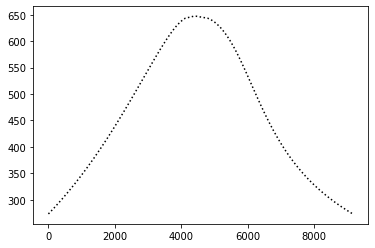

In [17]:
# Compute saturation curves
T_sample_sat = np.linspace(0.01 + 273.15, iapws95_light.Tc-0.01, 100)
sat_triples = [iapws95_light.prho_sat(T) for T in T_sample_sat]
psat_samples, rhol_samples, rhov_samples = zip(
  *[(tup["psat"], tup["rho_satl"], tup["rho_satv"])
  for tup in sat_triples])

# Compute dependent variables along saturation curves (the vapor dome properties)
sl, hl, ul, wl, pl = np.array([all_pure_lv(rhol, T)
                       for (rhol, T) in zip(rhol_samples, T_sample_sat)]).T
sv, hv, uv, wv, pv = np.array([all_pure_lv(rhov, T)
                       for (rhov, T) in zip(rhov_samples, T_sample_sat)]).T

s_vapor_dome = np.concatenate((sl, sv[::-1],))
T_vapor_dome = np.concatenate((T_sample_sat, T_sample_sat[::-1],))
plt.plot(s_vapor_dome, T_vapor_dome, 'k:')

In [18]:
# Compute isobar data at depth

T_depth_range = np.linspace(274, 1800, 200)

def rhos_isobar(T_range, p_depth, return_check=False):
  rho_depth = np.zeros_like(T_depth_range)
  s_depth = np.zeros_like(T_depth_range)
  p_depth_check = np.zeros_like(T_depth_range)

  for i, T in enumerate(T_range):
    rho_depth[i] = scipy.optimize.fsolve(
      lambda rho:all_pure_lv(rho, T)[4] / p_depth - 1.0,
      1000
    )
    s_depth[i], _, _, _, p_depth_check[i] = all_pure_lv(rho_depth[i], T)

  if return_check:
    return rho_depth, s_depth, p_depth_check
  else:
    return rho_depth, s_depth

p_depth = 100e6
rho_depth, s_depth, p_depth_check = rhos_isobar(
  T_depth_range, p_depth, return_check=True)

# Compute atmospheric boiling temperature
T_boil_atm = float(scipy.optimize.fsolve(
  lambda T: float(iapws95_light.prho_sat(T)["psat"]) / p_surf - 1,
                            273.15 + 100))

# Compute atmospheric pure liquid and pure vapor properties
psat_atm, rhol_atm, rhov_atm = iapws95_light.prho_sat(T_boil_atm).values()
sl_atm, hl_atm, _, _, _ = all_pure_lv(rhol_atm, T_boil_atm)
sv_atm, hv_atm, _, _, _ = all_pure_lv(rhov_atm, T_boil_atm)

In [19]:

def coflow_sim(gamma, z_range, x_surf1, x_surf2, rhov_atm, rhol_atm,
               T_boil_atm, hv_atm, hl_atm, p_surf, sv_atm, sl_atm, dpdz_avg):
  ''' Counterflow simulation.

  Input:
    gamma: heat loss parameter
    z_range: depth range (mesh)
    x_surf1: steam fraction of stream 1
    x_surf2: steam fraction of stream 2
    rhov_atm: pure vapor density at atmospheric conditions
    rhol_atm: pure liquid density at atmospheric conditions
    T_boil_atm: boiling temperature at atmospheric conditions
    hv_atm: pure vapor enthalpy at atmospheric conditions
    hl_atm: pure liquid enthalpy at atmospheric conditions
    p_surf: atmospheric pressure
    sv_atm: pure vapor entropy at atmospheric conditions
    sl_atm: pure liquid entropy at atmospheric conditions
    dpdz_avg: pressure gradient, averaged
   '''

  v1 = x_surf1 / rhov_atm + (1 - x_surf1) / rhol_atm
  v2 = x_surf2 / rhov_atm + (1 - x_surf2) / rhol_atm
  rho1 = 1 / v1
  rho2 = 1 / v2
  T1 = T_boil_atm
  T2 = T_boil_atm
  h1 = x_surf1 * hv_atm + (1 - x_surf1) * hl_atm
  h2 = x_surf2 * hv_atm + (1 - x_surf2) * hl_atm
  p1 = p_surf
  p2 = p_surf
  s1 = x_surf1 * sv_atm + (1 - x_surf1) * sl_atm
  s2 = x_surf2 * sv_atm + (1 - x_surf2) * sl_atm

  # Allocate
  rho2_path = np.zeros_like(z_range[:-1])
  T2_path = rho2_path.copy()
  p2_path = rho2_path.copy()
  h2_path = rho2_path.copy()
  x2_path = rho2_path.copy()
  s2_path = rho2_path.copy()
  rho1_path = rho2_path.copy()
  T1_path = rho2_path.copy()
  p1_path = rho2_path.copy()
  h1_path = rho2_path.copy()
  x1_path = rho2_path.copy()
  s1_path = rho2_path.copy()
  is_LV1 = x_surf1 > 0.0
  dz_range = z_range[1:] - z_range[:-1]

  x1 = -1
  x2 = -1

  def hp_residual(rho, T, h_target, p_target):
    ''' Root-finding residual vector for matching enthalpy and pressure. '''
    s, h, u, w, p = all_pure_lv(rho, T)
    return np.array([
      float(h) / h_target - 1.0,
      float(p) / p_target - 1.0,
    ])

  def Txvs_explicit(T_init, h_target, p_target, clip=True):
    ''' Compute (T,x, v) as function of (h, p) explicitly. Valid only if
    p < p_crit, T < T_crit.

    T_init is used as initial guess for finding T on the sat curve.
    '''
    # Compute T(p) directly at saturation
    T_target = float(scipy.optimize.fsolve(
      lambda T: float(iapws95_light.prho_sat(T)["psat"]) / p_target - 1.0,
      T_init))
    tup = iapws95_light.prho_sat(T_target)
    psat, rhol, rhov = (tup["psat"], tup["rho_satl"], tup["rho_satv"],)

    # Compute x directly using enthalpy
    sl, hl, _, _, _ = all_pure_lv(rhol, T_target)
    sv, hv, _, _, _ = all_pure_lv(rhov, T_target)
    x = (h_target - hl) / (hv - hl)
    if clip:
      x = np.clip(x, 0, 1)

    return T_target, x, x/rhov + (1-x)/rhol, x*sv + (1-x)*sl,

  for i, dz in enumerate(dz_range):
    # Comptue enthalpy rates
    dhdz1, dhdz2 = dhdz(rho1, T1, rho2, T2, gamma)

    # Step enthalpy, pressure
    h1 += dhdz1 * dz
    h2 += dhdz2 * dz
    dp = dz * dpdz_avg
    p1 += dp
    p2 += dp

    if p1 < iapws95_light.pc and is_LV1:
      T1, x1, v1, s1 = Txvs_explicit(T1, h1, p1)
      rho1 = 1/v1
      if x1 <= 0 or x1 >= 1:
        s1 = all_pure_lv(rho1, T1)[0]
        is_LV1 = False
    else:
      x1 = np.round(x1)
      # Solve h, p system
      rho1, T1 = scipy.optimize.fsolve(
        lambda rhoT: hp_residual(rhoT[0], rhoT[1], h1, p1),
        np.array([
          float(rho1 + 1 / all_pure_lv(rho1, T1)[3] **2 * dp), # rho estimate
          T1]))
      s1 = all_pure_lv(rho1, T1)[0]

    # Solve h, p system
    rho2, T2 = scipy.optimize.fsolve(
      lambda rhoT: hp_residual(rhoT[0], rhoT[1], h2, p2),
      np.array([
        float(rho2 + 1 / all_pure_lv(rho2, T2)[3] **2 * dp), # rho estimate
        T2]))
    s2 = all_pure_lv(rho2, T2)[0]

    rho1_path[i] = rho1
    p1_path[i] = p1
    T1_path[i] = T1
    h1_path[i] = h1
    x1_path[i] = x1
    s1_path[i] = s1

    rho2_path[i] = rho2
    p2_path[i] = p2
    T2_path[i] = T2
    h2_path[i] = h2
    x2_path[i] = x2
    s2_path[i] = s2

  return rho1_path, p1_path, T1_path, h1_path, x1_path, s1_path, \
    rho2_path, p2_path, T2_path, h2_path, x2_path, s2_path


In [20]:
# Setting heat transfer coupling coefficient
gamma = 0.1
# Set 1 as the hot stream with the following steam fraction
x_surf1 = 0.5
# Set 2 as the cold stream with the following steam fraction
x_surf2 = 0.0

# Set a nonlinearly distributed z mesh
dz = -10.0
z_range = z_base * np.linspace(0, 1, int(z_base//dz) + 1)**2

# Run counterflow simulation
soln_path = \
  coflow_sim(gamma, z_range, x_surf1, x_surf2, rhov_atm, rhol_atm,
              T_boil_atm, hv_atm, hl_atm, p_surf, sv_atm, sl_atm, dpdz_avg)

Hot path (right, high T to low T)
Cold path (left, low T to high T


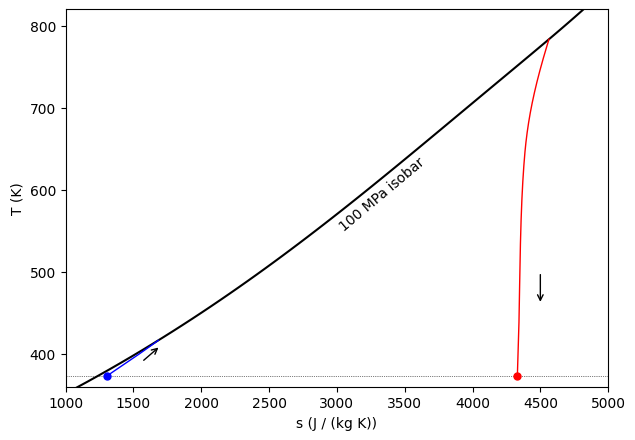

In [21]:
# Show the paths of the two pipes on the T-s diagram
plt.figure(figsize=(7,5), dpi=100)

# Plot isotherm for surface boiling temperature (horizontal dotted line)
plt.plot([0, 5000], [T_boil_atm, T_boil_atm], 'k:', linewidth=0.5)
# Plot isobar at depth (black curve)
plt.plot(s_depth[np.where(s_depth < 5000)],
         T_depth_range[np.where(s_depth < 5000)], 'k-')

# Unpack solution tuple
rho1_path, p1_path, T1_path, h1_path, x1_path, s1_path, \
  rho2_path, p2_path, T2_path, h2_path, x2_path, s2_path, = soln_path
# T-s for flow 1
plt.plot(s1_path, T1_path, 'r-', linewidth=1)
plt.plot(s1_path[0], T1_path[0], 'r.', markersize=10)
plt.annotate("", xytext=(4500, 500), xy=(4500, 460),
            arrowprops=dict(arrowstyle="->"))

# T-s for flow 2
plt.plot(s2_path, T2_path, 'b-', linewidth=1)
plt.plot(s2_path[0], T2_path[0], 'b.', markersize=10)
plt.annotate("", xytext=(1560, 390), xy=(1700, 410),
            arrowprops=dict(arrowstyle="->"))

plt.text(3000, 550, f"100 MPa isobar", rotation = 40)

plt.xlim(1000, 5000)
plt.ylim(360, 820)
plt.xlabel("s (J / (kg K))")
plt.ylabel("T (K)")

print("Hot path (right, high T to low T)")
print("Cold path (left, low T to high T")